<a href="https://colab.research.google.com/github/sainipuna/Edav-course-end-project/blob/main/Fuel_Price_Trend_Analysis_083_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fuel Price Trend Analysis and Visualization in India
**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn  
**Project type:** Data analysis and visualization

## 1. Introduction
Fuel prices influence transportation, household budgets, and the cost of moving goods. This project explores historical petrol and diesel prices in India, compares their trends, studies monthly and yearly changes, and visualizes the relationship between fuel prices and crude-oil prices where the dataset provides those fields.

## 2. Objectives
- Inspect and clean a fuel-price dataset.
- Use NumPy to calculate descriptive statistics.
- Use Pandas `groupby()` to compare average prices by year and fuel type.
- Handle missing values and check duplicates, invalid values, and potential outliers.
- Create line plots, bar plots, and a correlation heatmap.
- Summarize findings without claiming that correlation proves causation.

## 3. Dataset and source
The notebook loads a community-curated CSV from the public GitHub repository listed below. It includes date/month, petrol and diesel prices, and additional fields such as crude-oil price and exchange rate. Because this is a third-party consolidated dataset, treat it as a learning dataset and verify important figures against the Government of India's Petroleum Planning & Analysis Cell (PPAC).

- CSV: https://raw.githubusercontent.com/VigoraXGlobal/india-fuel-price-dashboard/main/fuel_history_final.csv
- Official reference: https://ppac.gov.in/index.php/retail-selling-price-rsp-of-petrol-diesel-and-domestic-lpg/rsp-of-petrol-and-diesel-in-metro-cities-since-16-6-2017

  https://docs.google.com/spreadsheets/d/1od1a1fXg8_unvGcAKTEI22T0c5cQCXu924Q3B9BbGh4/edit?usp=sharing


In [ ]:
%pip install numpy pandas matplotlib seaborn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

DATA_SOURCE = "https://raw.githubusercontent.com/VigoraXGlobal/india-fuel-price-dashboard/main/fuel_history_final.csv"
# To use a downloaded local copy instead, change the line above to:
# DATA_SOURCE = "fuel_history_final.csv"

df_raw = pd.read_csv(DATA_SOURCE)
print("Dataset loaded successfully.")
print("Shape (rows, columns):", df_raw.shape)
display(df_raw.head())

Dataset loaded successfully.
Shape (rows, columns): (1038, 17)


,date,year,month,petrol_price_inr,diesel_price_inr,crude_oil_price_usd,usd_inr_exchange_rate,petrol_price_usd,diesel_price_usd,inflation_adjusted_petrol,inflation_adjusted_diesel,monthly_change_pct_petrol,monthly_change_pct_diesel,government_regime,event_flag,event_description,petrol_diesel_difference
0,1940-01-01,1940,1,0.21,0.12,1.01,3.31,0.0634,0.0363,7.00,4.00,0.0000,0.0000,Pre-Independence / Colonial Pricing,0,NaN,0.09
1,1940-02-01,1940,2,0.14,0.12,1.02,3.31,0.0423,0.0363,4.65,3.99,-33.3333,0.0000,Pre-Independence / Colonial Pricing,0,NaN,0.02
2,1940-03-01,1940,3,0.18,0.13,1.02,3.31,0.0544,0.0393,5.96,4.31,28.5714,8.3333,Pre-Independence / Colonial Pricing,0,NaN,0.05
3,1940-04-01,1940,4,0.22,0.10,1.02,3.31,0.0665,0.0302,7.27,3.30,22.2222,-23.0769,Pre-Independence / Colonial Pricing,0,NaN,0.12
4,1940-05-01,1940,5,0.20,0.10,1.01,3.31,0.0604,0.0302,6.58,3.29,-9.0909,0.0000,Pre-Independence / Colonial Pricing,0,NaN,0.10


In [ ]:
print("Column names:")
print(df_raw.columns.tolist())

print("\\nData types:")
display(df_raw.dtypes.to_frame("data_type"))

print("\\nMissing values by column:")
display(df_raw.isna().sum().to_frame("missing_count"))

print("\\nExact duplicate rows:", df_raw.duplicated().sum())
display(df_raw.describe(include="all").T)

Column names:
['date', 'year', 'month', 'petrol_price_inr', 'diesel_price_inr', 'crude_oil_price_usd', 'usd_inr_exchange_rate', 'petrol_price_usd', 'diesel_price_usd', 'inflation_adjusted_petrol', 'inflation_adjusted_diesel', 'monthly_change_pct_petrol', 'monthly_change_pct_diesel', 'government_regime', 'event_flag', 'event_description', 'petrol_diesel_difference']
\nData types:


,data_type
date,object
year,int64
month,int64
petrol_price_inr,float64
diesel_price_inr,float64
crude_oil_price_usd,float64
usd_inr_exchange_rate,float64
petrol_price_usd,float64
diesel_price_usd,float64
inflation_adjusted_petrol,float64


\nMissing values by column:


,missing_count
date,0
year,0
month,0
petrol_price_inr,0
diesel_price_inr,0
crude_oil_price_usd,0
usd_inr_exchange_rate,0
petrol_price_usd,0
diesel_price_usd,0
inflation_adjusted_petrol,0


\nExact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,1038,1038,2026-06-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,1038.0,NaN,NaN,NaN,1982.751445,24.983271,1940.0,1961.0,1983.0,2004.0,2026.0
month,1038.0,NaN,NaN,NaN,6.482659,3.453673,1.0,3.0,6.0,9.0,12.0
petrol_price_inr,1038.0,NaN,NaN,NaN,18.949277,29.242094,0.14,0.4825,3.105,21.4625,101.21
diesel_price_inr,1038.0,NaN,NaN,NaN,14.109595,23.580318,0.09,0.28,1.875,14.4825,88.22
crude_oil_price_usd,1038.0,NaN,NaN,NaN,27.047832,30.072762,0.97,2.94,16.63,39.0425,133.65
usd_inr_exchange_rate,1038.0,NaN,NaN,NaN,25.786676,25.285474,3.29,4.77,10.075,45.29,85.54
petrol_price_usd,1038.0,NaN,NaN,NaN,0.390792,0.388498,0.0423,0.09435,0.2767,0.474775,1.3595
diesel_price_usd,1038.0,NaN,NaN,NaN,0.272397,0.302203,0.0272,0.0547,0.175,0.32035,1.1185
inflation_adjusted_petrol,1038.0,NaN,NaN,NaN,45.227929,49.60607,4.65,7.615,20.8,65.0925,160.86


In [ ]:
df = df_raw.copy()
df.columns = df.columns.str.strip().str.lower()

# Convert date to datetime; invalid dates become NaT and are reported.
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert likely numeric fields to numbers safely.
numeric_candidates = [
    "year", "month", "petrol_price_inr", "diesel_price_inr",
    "crude_oil_price_usd", "usd_inr_exchange_rate", "petrol_price_usd",
    "diesel_price_usd", "inflation_adjusted_petrol", "inflation_adjusted_diesel",
    "monthly_change_pct_petrol", "monthly_change_pct_diesel",
    "petrol_diesel_difference"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

before_rows = len(df)
df = df.drop_duplicates().copy()
print("Exact duplicate rows removed:", before_rows - len(df))

if "date" in df.columns:
    invalid_dates = df["date"].isna().sum()
    print("Rows with invalid/missing dates:", invalid_dates)
    df = df.dropna(subset=["date"]).copy()

price_cols = [c for c in ["petrol_price_inr", "diesel_price_inr"] if c in df.columns]
for col in price_cols:
    invalid = (df[col] <= 0).sum()
    print(f"Non-positive values in {col}:", invalid)
    # Non-positive retail prices are treated as invalid records.
    df.loc[df[col] <= 0, col] = np.nan

# Re-create year/month from date where available, so they match the parsed date.
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

print("Cleaned shape:", df.shape)
display(df.head())

Exact duplicate rows removed: 0
Rows with invalid/missing dates: 0
Non-positive values in petrol_price_inr: 0
Non-positive values in diesel_price_inr: 0
Cleaned shape: (1038, 17)


,date,year,month,petrol_price_inr,diesel_price_inr,crude_oil_price_usd,usd_inr_exchange_rate,petrol_price_usd,diesel_price_usd,inflation_adjusted_petrol,inflation_adjusted_diesel,monthly_change_pct_petrol,monthly_change_pct_diesel,government_regime,event_flag,event_description,petrol_diesel_difference
0,1940-01-01,1940,1,0.21,0.12,1.01,3.31,0.0634,0.0363,7.00,4.00,0.0000,0.0000,Pre-Independence / Colonial Pricing,0,NaN,0.09
1,1940-02-01,1940,2,0.14,0.12,1.02,3.31,0.0423,0.0363,4.65,3.99,-33.3333,0.0000,Pre-Independence / Colonial Pricing,0,NaN,0.02
2,1940-03-01,1940,3,0.18,0.13,1.02,3.31,0.0544,0.0393,5.96,4.31,28.5714,8.3333,Pre-Independence / Colonial Pricing,0,NaN,0.05
3,1940-04-01,1940,4,0.22,0.10,1.02,3.31,0.0665,0.0302,7.27,3.30,22.2222,-23.0769,Pre-Independence / Colonial Pricing,0,NaN,0.12
4,1940-05-01,1940,5,0.20,0.10,1.01,3.31,0.0604,0.0302,6.58,3.29,-9.0909,0.0000,Pre-Independence / Colonial Pricing,0,NaN,0.10


## Q1. Use NumPy to calculate mean, minimum, and maximum fuel prices
**Concept explanation:** NumPy provides efficient numerical operations such as `mean()`, `min()`, and `max()`. Here we calculate summary statistics for petrol and diesel prices separately after ignoring missing values.

**Interpretation:** Compare the averages and ranges. A higher mean indicates a higher typical recorded price in the selected dataset period. Minimum and maximum values help show the historical range, but the full range may span different economic and pricing regimes.

In [ ]:
price_summary = {}
for col in ["petrol_price_inr", "diesel_price_inr"]:
    if col in df.columns:
        values = df[col].dropna().to_numpy(dtype=float)
        if values.size:
            price_summary[col] = {
                "observations": int(values.size),
                "mean": float(np.mean(values)),
                "minimum": float(np.min(values)),
                "maximum": float(np.max(values)),
                "median": float(np.median(values))
            }

q1_summary = pd.DataFrame(price_summary).T
display(q1_summary.round(2))

,observations,mean,minimum,maximum,median
petrol_price_inr,1038.0,18.95,0.14,101.21,3.10
diesel_price_inr,1038.0,14.11,0.09,88.22,1.88


**Conclusion / insight:** Use the displayed summary to state which fuel has the higher mean in this dataset and report its minimum and maximum. Remember that these are nominal prices unless the selected column explicitly says inflation-adjusted.

## Q2. Use Pandas groupby to compare yearly petrol and diesel prices
**Concept explanation:** `groupby()` splits observations into groups and applies an aggregation such as mean, minimum, or maximum. Grouping by year helps identify long-term price changes.

We calculate annual average prices and the year-over-year percentage change in annual averages.

In [ ]:
annual_avg = df.groupby("year")[price_cols].mean(numeric_only=True).sort_index()
annual_avg = annual_avg.rename(columns={
    "petrol_price_inr": "petrol_avg_inr",
    "diesel_price_inr": "diesel_avg_inr"
})
display(annual_avg.tail(15).round(2))

annual_change = annual_avg.pct_change() * 100
annual_change = annual_change.rename(columns={
    "petrol_avg_inr": "petrol_yoy_change_pct",
    "diesel_avg_inr": "diesel_yoy_change_pct"
})
display(annual_change.tail(15).round(2))

,petrol_avg_inr,diesel_avg_inr
year,,
2012,65.98,39.00
2013,68.91,44.75
2014,70.40,47.17
2015,60.69,40.03
2016,59.93,39.54
2017,62.93,45.53
2018,73.62,58.22
2019,73.28,65.89
2020,70.83,63.44


,petrol_yoy_change_pct,diesel_yoy_change_pct
year,,
2012,9.88,13.93
2013,4.45,14.74
2014,2.15,5.40
2015,-13.79,-15.13
2016,-1.26,-1.23
2017,5.01,15.16
2018,16.99,27.87
2019,-0.46,13.17
2020,-3.34,-3.71


**Conclusion / insight:** Describe whether the annual averages generally rise, fall, or fluctuate. Mention any years with notable increases or decreases visible in the table. Annual averages smooth daily/monthly changes, so they do not show every short-term price movement.

## Q3. Handle missing values and check anomalies/outliers
**Concept explanation:** Missing values can prevent calculations and plots from working. For time-series prices, interpolation can be useful for short internal gaps, but it should not be used to invent large stretches of missing history. We report missingness first, then fill only short gaps by time interpolation. We also flag possible outliers using the IQR rule.

**Important:** An IQR outlier is a value that is unusual relative to the distribution; it is not automatically an error. Fuel prices can legitimately change because of taxes, policy, currency movements, and market conditions.

In [ ]:
print("Missing values before imputation:")
display(df[price_cols].isna().sum().to_frame("missing_before"))

# Sort by date before time interpolation. Limit=2 fills only short gaps of up to 2 consecutive records.
df = df.sort_values("date").set_index("date")
for col in price_cols:
    df[col] = df[col].interpolate(method="time", limit=2, limit_area="inside")
df = df.reset_index()

print("Missing values after short-gap interpolation:")
display(df[price_cols].isna().sum().to_frame("missing_after"))

Missing values before imputation:


,missing_before
petrol_price_inr,0
diesel_price_inr,0


Missing values after short-gap interpolation:


,missing_after
petrol_price_inr,0
diesel_price_inr,0


In [ ]:
def iqr_outlier_report(series):
    s = series.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = s[(s < lower) | (s > upper)]
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "lower_fence": lower, "upper_fence": upper,
        "outlier_count": int(flagged.size)
    })

outlier_results = pd.DataFrame({
    col: iqr_outlier_report(df[col]) for col in price_cols
}).T
display(outlier_results.round(2))

,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count
petrol_price_inr,0.48,21.46,20.98,-30.99,52.93,193.0
diesel_price_inr,0.28,14.48,14.20,-21.02,35.79,176.0


**Conclusion / insight:** Report the number of missing prices before and after short-gap interpolation and the number of IQR-flagged values. Do not delete outliers automatically; inspect them against the source and historical context. Missing values at the beginning/end of a series may remain because interpolation is limited to internal short gaps.

## Q4. Group by year and month to compute descriptive statistics
**Concept explanation:** Grouping by year and month allows us to compare typical prices and variability across time. This section reports monthly average prices and annual count/mean/minimum/maximum statistics.

In [ ]:
monthly_avg = (
    df.assign(month_start=df["date"].dt.to_period("M").dt.to_timestamp())
      .groupby("month_start")[price_cols]
      .mean()
      .sort_index()
)
display(monthly_avg.tail(12).round(2))

annual_stats = df.groupby("year")[price_cols].agg(["count", "mean", "min", "max"])
display(annual_stats.tail(10).round(2))

,petrol_price_inr,diesel_price_inr
month_start,,
2025-07-01,96.69,83.13
2025-08-01,96.71,83.17
2025-09-01,96.74,83.16
2025-10-01,96.84,83.21
2025-11-01,96.86,83.22
2025-12-01,96.91,83.24
2026-01-01,97.60,84.05
2026-02-01,97.59,84.04
2026-03-01,97.63,84.07


petrol_price_inr                       diesel_price_inr                     
                count   mean    min     max            count   mean    min    max
year                                                                             
2017               12  62.93  61.33   64.88               12  45.53  44.26  47.15
2018               12  73.62  71.45   76.04               12  58.22  56.39  60.30
2019               12  73.28  72.60   73.99               12  65.89  65.58  66.23
2020               12  70.83  68.03   73.04               12  63.44  61.29  65.60
2021               12  83.38  75.01   91.73               12  73.93  67.20  80.64
2022               12  97.01  93.57  101.21               12  83.48  81.18  88.22
2023               12  97.33  97.04   97.64               12  83.27  83.05  83.49
2024               12  96.14  96.03   96.25               12  82.63  82.50  82.71
2025               12  96.70  96.53   96.91               12  83.13  83.02  83.24
2026                6  97.68  97.59   97.85                6  84.11  84.04  84.18

**Conclusion / insight:** Use monthly averages to identify short-term movements and annual descriptive statistics to summarize each year. Differences in observation counts can reflect the dataset's coverage and should be mentioned when comparing years.

## Q5. Visualize fuel price trends using line plots, bar plots, and a heatmap
**Concept explanation:** A line plot is appropriate for time-series trends; a bar plot compares yearly averages; a heatmap uses color intensity to show the pattern of monthly averages by year. Axes and units are labelled to make the figures understandable.

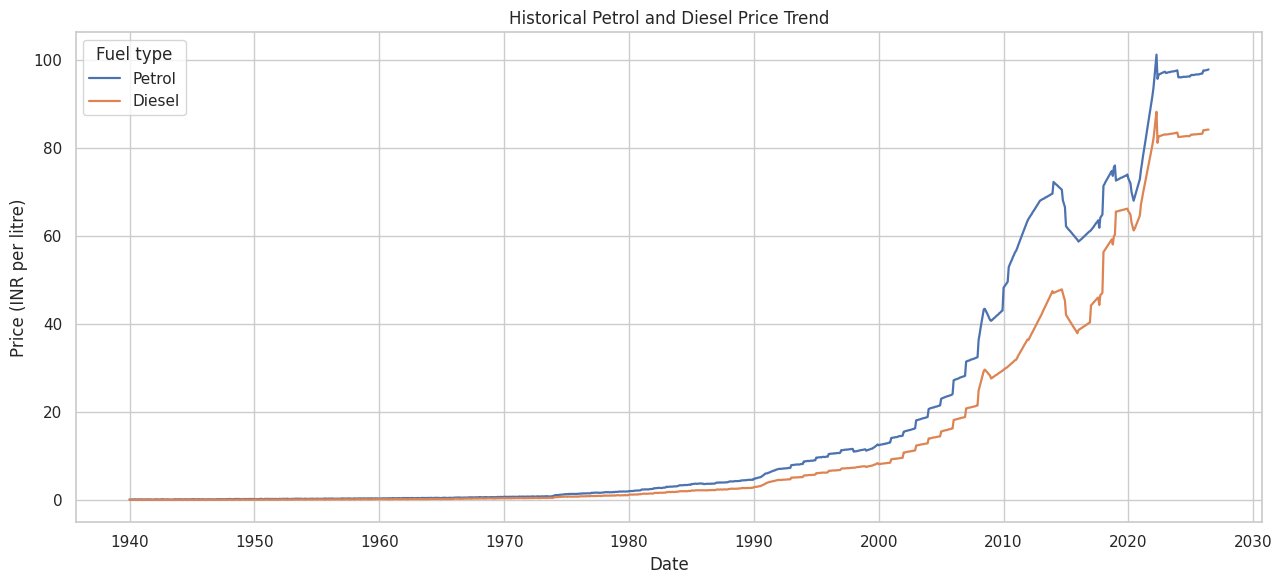

In [ ]:
# Plot 1: full monthly trend
fig, ax = plt.subplots(figsize=(13, 6))
for col, label in [("petrol_price_inr", "Petrol"), ("diesel_price_inr", "Diesel")]:
    if col in df.columns:
        ax.plot(df["date"], df[col], label=label, linewidth=1.6)
ax.set_title("Historical Petrol and Diesel Price Trend")
ax.set_xlabel("Date")
ax.set_ylabel("Price (INR per litre)")
ax.legend(title="Fuel type")
plt.tight_layout()
plt.show()

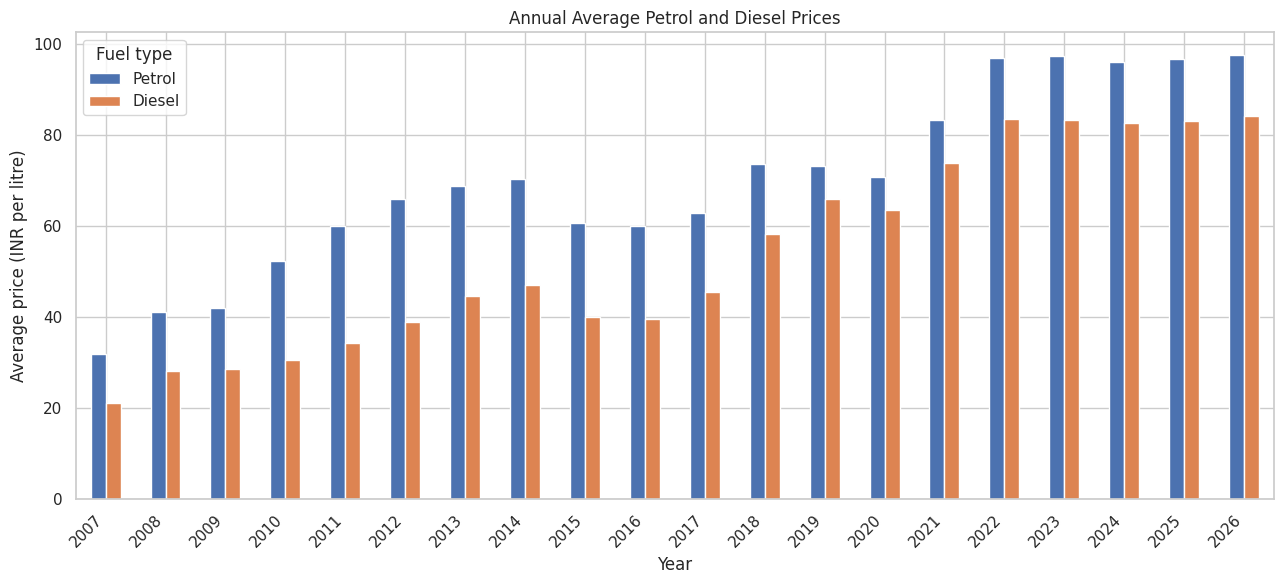

In [ ]:
# Plot 2: yearly average comparison (use the most recent 20 years available)
yearly_plot = annual_avg.tail(20)
ax = yearly_plot.plot(kind="bar", figsize=(13, 6))
ax.set_title("Annual Average Petrol and Diesel Prices")
ax.set_xlabel("Year")
ax.set_ylabel("Average price (INR per litre)")
ax.legend(["Petrol", "Diesel"], title="Fuel type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

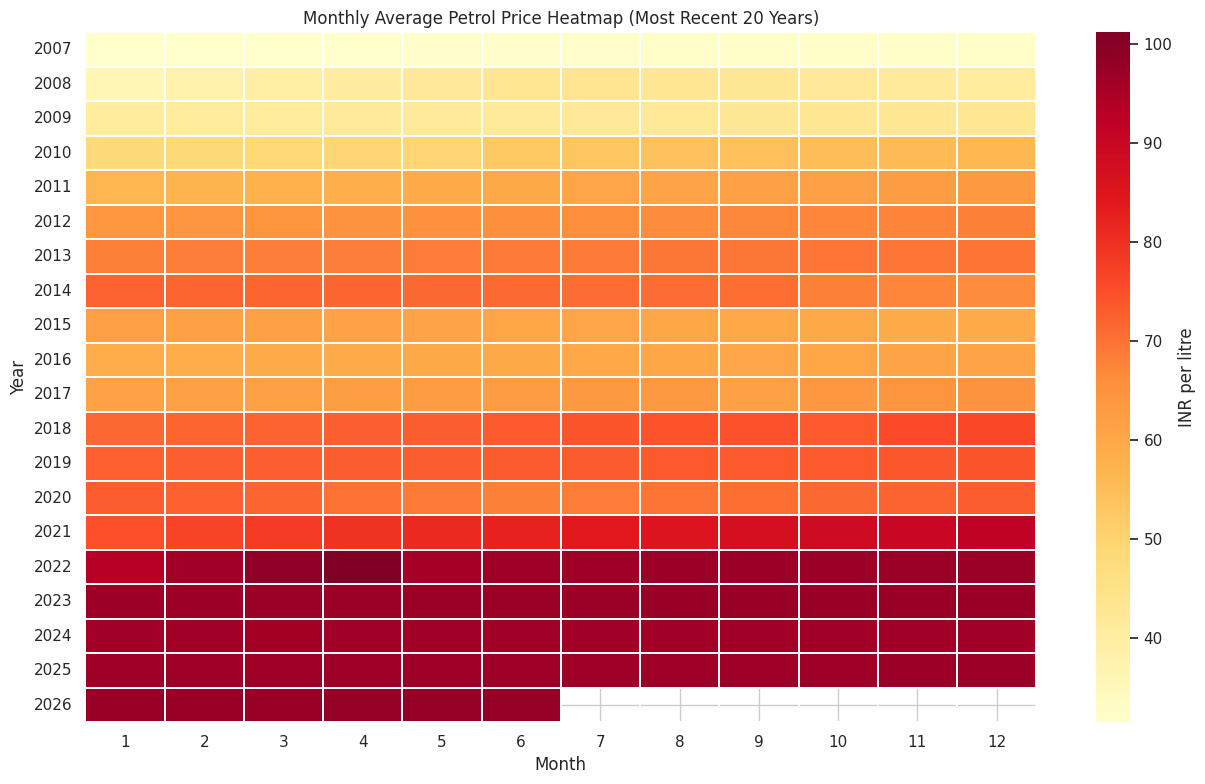

In [ ]:
# Plot 3: heatmap of monthly average petrol prices by year
heat_source = df[["date", "petrol_price_inr"]].dropna().copy()
heat_source["year"] = heat_source["date"].dt.year
heat_source["month"] = heat_source["date"].dt.month
heat_pivot = heat_source.pivot_table(
    index="year", columns="month", values="petrol_price_inr", aggfunc="mean"
)
# Keep the most recent 20 years for legibility.
heat_pivot = heat_pivot.tail(20)
plt.figure(figsize=(13, 8))
sns.heatmap(heat_pivot, cmap="YlOrRd", linewidths=0.2, cbar_kws={"label": "INR per litre"})
plt.title("Monthly Average Petrol Price Heatmap (Most Recent 20 Years)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

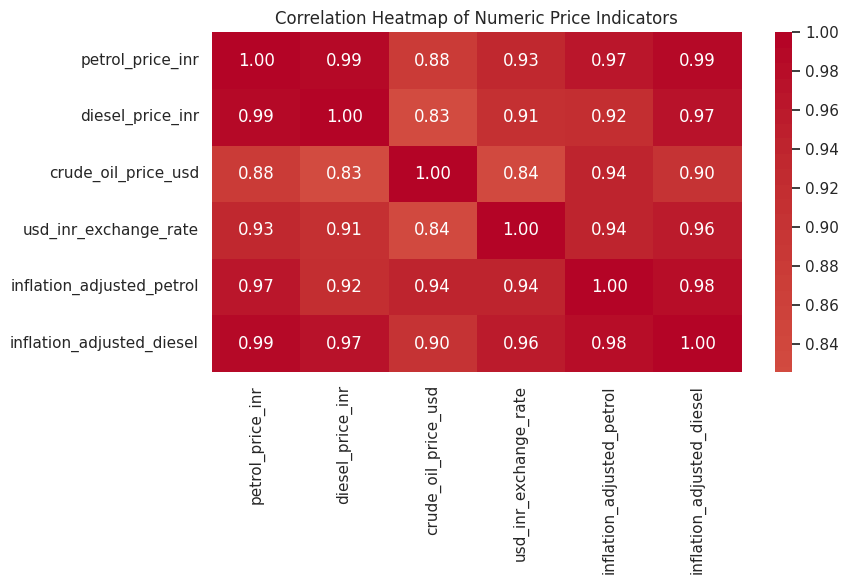

In [ ]:
# Optional: correlation heatmap for numeric columns available in the dataset.
corr_cols = [c for c in [
    "petrol_price_inr", "diesel_price_inr", "crude_oil_price_usd",
    "usd_inr_exchange_rate", "inflation_adjusted_petrol", "inflation_adjusted_diesel"
] if c in df.columns]
if len(corr_cols) >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("Correlation Heatmap of Numeric Price Indicators")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

## 7. Overall conclusion
This project used NumPy and Pandas to summarize historical fuel prices, clean missing/invalid entries, inspect possible outliers, aggregate values by year and month, and create visualizations. The analysis helps identify long-term movements and differences between petrol and diesel.

The results depend on the coverage and reliability of the source dataset. Fuel prices are affected by multiple factors, including international oil prices, exchange rates, central and state taxes, freight, and policy changes. This notebook is descriptive, not a causal model or a price forecast.

## 8. Limitations and future scope
- Verify important figures against official PPAC records.
- Restrict comparisons to a consistent city, fuel type, and time period where possible.
- Add official metro-city data to compare price differences across locations.
- Add inflation-adjusted values for a more meaningful long-run comparison.
- A future project could test forecasting methods, but forecasts should be evaluated on held-out data.

## References
1. VigoraXGlobal, `fuel_history_final.csv`, public GitHub repository: https://github.com/VigoraXGlobal/india-fuel-price-dashboard
2. Petroleum Planning & Analysis Cell (PPAC), Government of India, Retail Selling Price of Petrol and Diesel in Metro Cities: https://ppac.gov.in/index.php/retail-selling-price-rsp-of-petrol-diesel-and-domestic-lpg/rsp-of-petrol-and-diesel-in-metro-cities-since-16-6-2017

   3.https://docs.google.com/spreadsheets/d/1od1a1fXg8_unvGcAKTEI22T0c5cQCXu924Q3B9BbGh4/edit?usp=sharing
